In [1]:
!pip install -q fastai fastbook

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 43.1 MB/s eta 0:00:00


In [2]:
!pip install -q ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 28.6 MB/s eta 0:00:00


In [3]:
from fastbook import *
from ddgs import DDGS
def search_images(term, max_images=50):
  results = DDGS().images(term, max_results=max_images)
  return [r['image'] for r in results]


In [4]:
urls = search_images('bird photos', max_images=1)
urls[0]

'https://images.pexels.com/photos/326900/pexels-photo-326900.jpeg?cs=srgb&dl=wood-flight-bird-326900.jpg&fm=jpg'

In [5]:
dest = Path('bird.jpg')
if not dest.exists():
  download_url(urls[0], dest, show_progress=False)

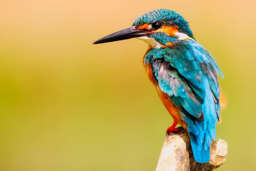

In [6]:
im = Image.open(dest)
im.to_thumb(256,256)

an image URL is only a reference to an image online. T work with it locally, I can download it using "download_url()" and save it to a file

In [7]:
searches = 'forest', 'bird'
path = Path('bird_or_not')


for o in searches:
  dest = (path/o)
  dest.mkdir(exist_ok=True, parents=True)
  download_images(dest, urls=search_images(f'{o} photo'))
  time.sleep(5)
  resize_images(path/o, max_size=400, dest=path/o)

In [8]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

0

In [9]:
from fastai.vision.all import *
path = Path('bird_or_not')
print("Bird images:", len(get_image_files(path/'bird')))
print("Forest images:", len(get_image_files(path/'forest')))

Bird images: 31
Forest images: 34


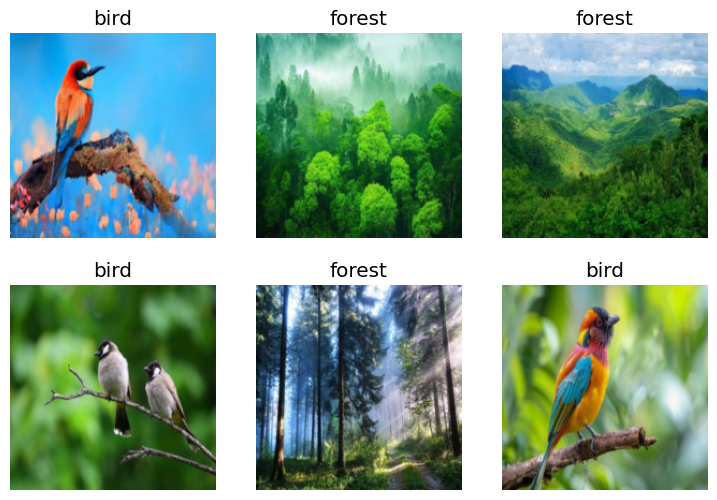

In [10]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

approximately 80% of the images are used for training, and 20% for validation.

In [11]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 114MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.564890,0.691754,0.384615,00:06


epoch,train_loss,valid_loss,error_rate,time
0,1.811749,0.529436,0.230769,00:08
1,1.324735,0.211856,0.153846,00:07
2,0.909660,0.085153,0.000000,00:08


fine-tuning adjusts a pretrained model so it becomes better at the particular classification problem.
in fastai, "fine tune(3)" normally trains the new classification head first and then fine-tunes the model for three more epochs

In [12]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f}")

This is a: bird.
Probability it's a bird: 1.0000


**My Experiments**

In [15]:
label, _, probs = learn.predict(PILImage.create('test_bird.jpg'))
print(label)
print(probs)

bird
tensor([9.9917e-01, 8.3392e-04])


the output:
this called scientific notation.
- 9.9922e-01 = 0.99922 = 99.922%
- 7.7977e-04 = 0.00077977 = approximately 0.078%
- tensor() means PyTorch is storing these numbers in a tensor, a data structure commonly used in deep learning.

In [17]:
for category, probability in zip(learn.dls.vocab, probs):
    print(f'{category}: {probability:.2%}')

bird: 3.54%
forest: 96.46%


In [16]:
label, _, probs = learn.predict(
    PILImage.create('test_forest.jpg')
)

print(label)
print(probs)

forest
tensor([0.0354, 0.9646])


In [18]:
label, _, probs = learn.predict(
    PILImage.create('test_mixed.jpg')
)

print(label)
print(probs)

bird
tensor([9.9994e-01, 5.7624e-05])
